# Markov Chains

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_FOLDER = "data"
OUTPUT_FOLDER = "outputs"

STATES = ["dairy", "drinks", "fruit", "spices", "checkout"]
TERMINAL_STATE = "checkout"
LARGE_N = 100

## 1. Loading and cleaning the data

In [ ]:
def read_csv_flexible(path):
    """Read a CSV using ';' first, then ',' if needed."""
    try:
        df = pd.read_csv(path, sep=";")
        if len(df.columns) == 1:
            df = pd.read_csv(path)
    except Exception:
        df = pd.read_csv(path)
    return df

csv_files = glob.glob(os.path.join(DATA_FOLDER, "*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {DATA_FOLDER}.")

frames = []
for file in csv_files:
    daily = read_csv_flexible(file)
    daily["day"] = os.path.splitext(os.path.basename(file))[0]
    frames.append(daily)
data = pd.concat(frames, ignore_index=True)

data.columns = [str(c).strip().lower() for c in data.columns]
required_columns = {"timestamp", "customer_no", "location"}
missing_columns = required_columns - set(data.columns)
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

rows_before = len(data)
data["timestamp"] = pd.to_datetime(data["timestamp"], errors="coerce")
data["customer_no"] = pd.to_numeric(data["customer_no"], errors="coerce")
data["location"] = data["location"].astype("string").str.strip().str.lower()
data = data.dropna(subset=["timestamp", "customer_no", "location"]).copy()
data = data[data["location"].isin(STATES)].copy()

# Remove exact duplicate records only (repeated visits to a location are kept).
key = ["day", "timestamp", "customer_no", "location"]
duplicate_count = data.duplicated(subset=key).sum()
data = data.drop_duplicates(subset=key).copy()

print("Rows before cleaning:", rows_before)
print("Exact duplicate records removed:", duplicate_count)
print("Rows after cleaning:", len(data))
print("Missing values after cleaning:")
print(data[["timestamp", "customer_no", "location"]].isna().sum())
print("\nDataset shape:", data.shape)
print("Unique customer IDs:", data["customer_no"].nunique())
print("Days represented:", data["day"].nunique())
print("States in data:", sorted(data["location"].unique()))
print("\nRecords by state:")
print(data["location"].value_counts().reindex(STATES, fill_value=0))
print("\nFirst records:")
display(data.head())

Rows before cleaning: 24877
Exact duplicate records removed: 0
Rows after cleaning: 24877
Missing values after cleaning:
timestamp      0
customer_no    0
location       0
dtype: int64

Dataset shape: (24877, 4)
Unique customer IDs: 1535
Days represented: 5
States in data: ['checkout', 'dairy', 'drinks', 'fruit', 'spices']

Records by state:
location
dairy       4679
drinks      3905
fruit       5122
spices      3754
checkout    7417
Name: count, dtype: Int64

First records:


,timestamp,customer_no,location,day
0,2019-09-04 07:00:00,1,fruit,wednesday
1,2019-09-04 07:00:00,2,dairy,wednesday
2,2019-09-04 07:00:00,3,fruit,wednesday
3,2019-09-04 07:00:00,4,fruit,wednesday
4,2019-09-04 07:00:00,5,dairy,wednesday


## 2. Customer journeys

Customer IDs repeat across days, so a journey is identified by (day, customer). Each journey is cut at the first Checkout visit.

In [ ]:
data = data.sort_values(["day", "customer_no", "timestamp"], kind="stable").reset_index(drop=True)

journey_series = data.groupby(["day", "customer_no"], sort=False)["location"].apply(list)

def truncate_at_first_checkout(path):
    """Keep the path up to and including the first checkout."""
    if TERMINAL_STATE in path:
        return path[:path.index(TERMINAL_STATE) + 1]
    return path

journeys = journey_series.apply(truncate_at_first_checkout)
journeys = journeys[journeys.apply(len) > 0]

print("Customer-day journeys:", len(journeys))
print("Average recorded states per journey:", round(journeys.apply(len).mean(), 3))
print("Journey length summary:")
display(journeys.apply(len).describe().to_frame("journey_length"))

Customer-day journeys: 7445
Average recorded states per journey: 3.341
Journey length summary:


,journey_length
count,7445.000000
mean,3.341437
std,1.802592
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,18.000000


## 3. Transition counts and transition matrix

In [ ]:
transition_records = []
for (day, customer), path in journeys.items():
    for current_state, next_state in zip(path[:-1], path[1:]):
        transition_records.append({
            "day": day,
            "customer_no": customer,
            "location": current_state,
            "next_location": next_state,
        })

transitions = pd.DataFrame(
    transition_records,
    columns=["day", "customer_no", "location", "next_location"],
)

transition_counts = (
    transitions.groupby(["location", "next_location"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=STATES, columns=STATES, fill_value=0)
)

print("Transition counts:")
display(transition_counts)

# Probabilities = counts divided by the row total.
outgoing_counts = transition_counts.sum(axis=1)
P = transition_counts.div(outgoing_counts.replace(0, np.nan), axis=0)

# A state with no observed outgoing transitions becomes a self-loop.
# Checkout is absorbing.
for state in STATES:
    if outgoing_counts[state] == 0:
        P.loc[state, :] = 0.0
        P.loc[state, state] = 1.0

P.loc[TERMINAL_STATE, :] = 0.0
P.loc[TERMINAL_STATE, TERMINAL_STATE] = 1.0
P = P.reindex(index=STATES, columns=STATES).fillna(0.0)

print("\nOne-step transition matrix P:")
display(P.round(4))

print("\nRow sums (must all equal 1):")
display(P.sum(axis=1).round(8).to_frame("row_sum"))
assert np.allclose(P.sum(axis=1).to_numpy(), 1.0), "A row of P does not sum to 1."

Transition counts:


next_location,dairy,drinks,fruit,spices,checkout
location,,,,,
dairy,0,1041,886,913,1825
drinks,106,0,855,846,2096
fruit,1219,697,0,644,2555
spices,1213,1024,571,0,941
checkout,0,0,0,0,0



One-step transition matrix P:


next_location,dairy,drinks,fruit,spices,checkout
location,,,,,
dairy,0.0000,0.2232,0.1899,0.1957,0.3912
drinks,0.0272,0.0000,0.2191,0.2168,0.5370
fruit,0.2383,0.1363,0.0000,0.1259,0.4995
spices,0.3236,0.2731,0.1523,0.0000,0.2510
checkout,0.0000,0.0000,0.0000,0.0000,1.0000



Row sums (must all equal 1):


,row_sum
location,
dairy,1.0
drinks,1.0
fruit,1.0
spices,1.0
checkout,1.0


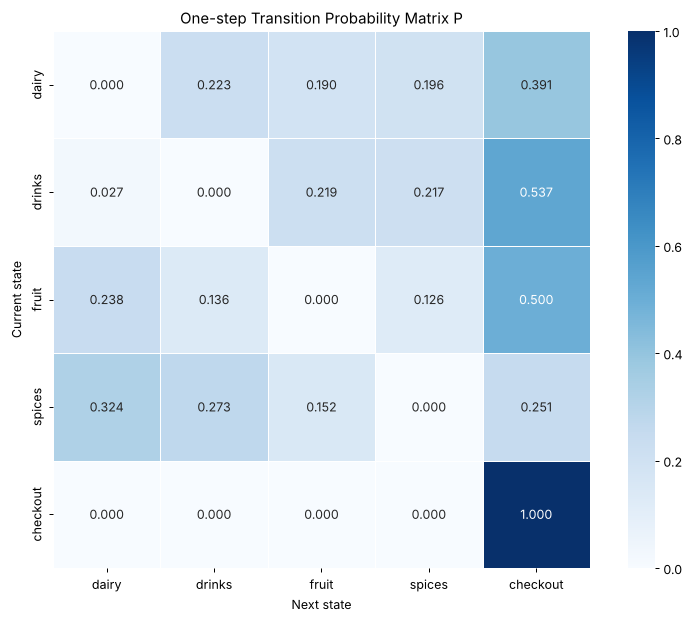

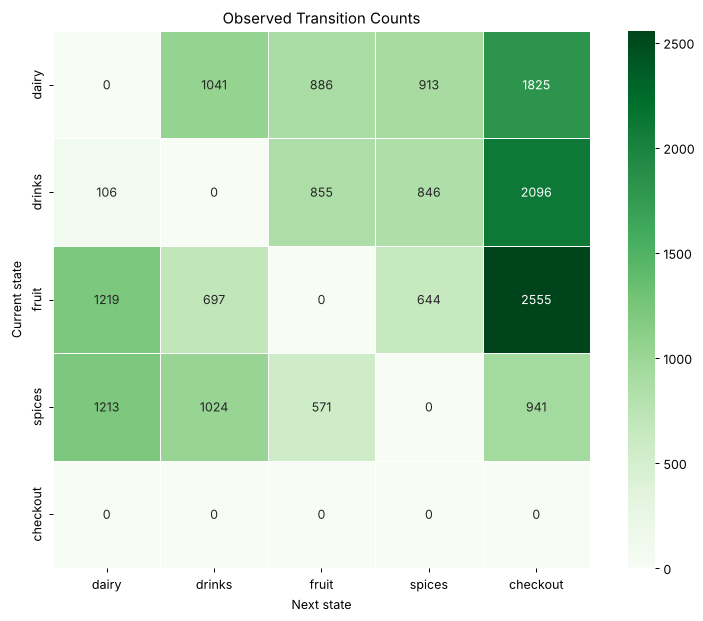

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(P, annot=True, fmt=".3f", cmap="Blues",
            vmin=0, vmax=1, linewidths=0.5, square=True)
plt.title("One-step Transition Probability Matrix P")
plt.xlabel("Next state")
plt.ylabel("Current state")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(transition_counts, annot=True, fmt="d", cmap="Greens",
            linewidths=0.5, square=True)
plt.title("Observed Transition Counts")
plt.xlabel("Next state")
plt.ylabel("Current state")
plt.tight_layout()
plt.show()

## 4. State transition diagram

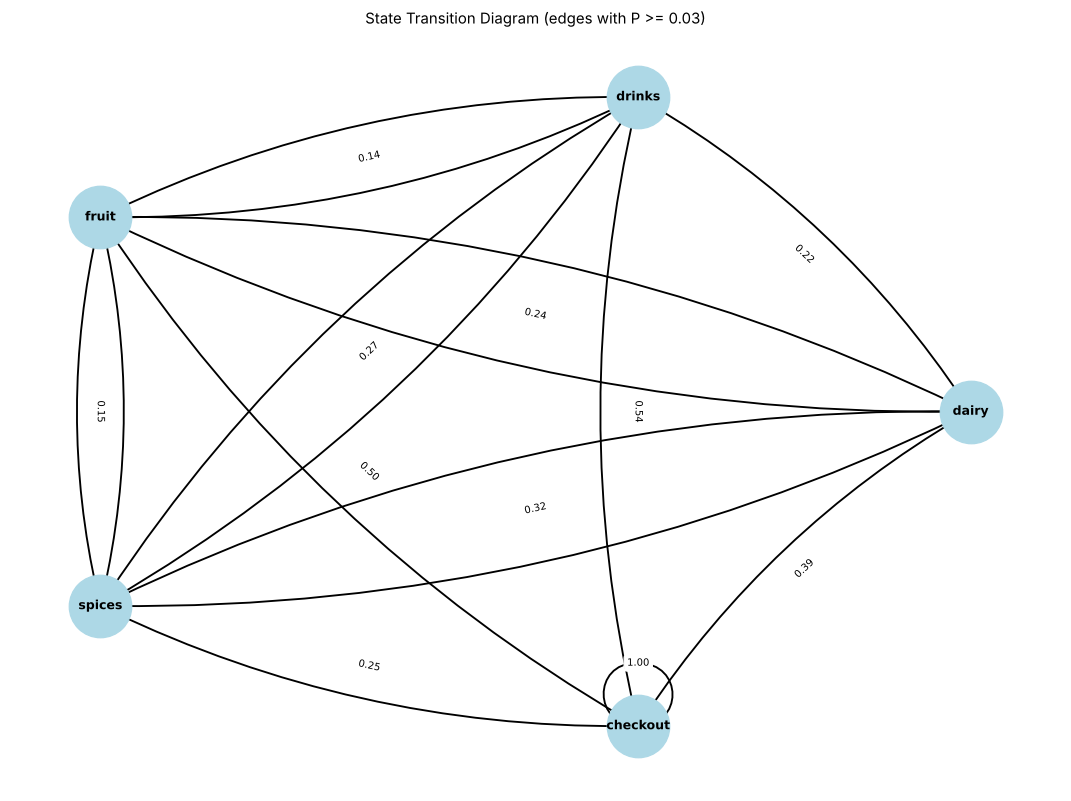

In [ ]:
import networkx as nx

EDGE_THRESHOLD = 0.03  # hide very small probabilities for readability
G = nx.DiGraph()
G.add_nodes_from(STATES)
for s1 in STATES:
    for s2 in STATES:
        prob = float(P.loc[s1, s2])
        if prob >= EDGE_THRESHOLD:
            G.add_edge(s1, s2, probability=prob, label=f"{prob:.2f}")

pos = nx.circular_layout(G)
plt.figure(figsize=(12, 9))
nx.draw_networkx_nodes(G, pos, node_size=2500, node_color="lightblue")
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")
nx.draw_networkx_edges(
    G, pos, arrows=True, arrowstyle="-|>", arrowsize=22,
    width=1.5, connectionstyle="arc3,rad=0.12",
)
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=8
)
plt.title(f"State Transition Diagram (edges with P >= {EDGE_THRESHOLD})")
plt.axis("off")
plt.tight_layout()
plt.show()

## 5. n-step transition probabilities


P^2:


next_location,dairy,drinks,fruit,spices,checkout
location,,,,,
dairy,0.1146,0.0793,0.0787,0.0723,0.6550
drinks,0.1223,0.0951,0.0382,0.0329,0.7115
fruit,0.0444,0.0876,0.0943,0.0762,0.6975
spices,0.0437,0.0930,0.1213,0.1417,0.6003
checkout,0.0000,0.0000,0.0000,0.0000,1.0000



P^3:


next_location,dairy,drinks,fruit,spices,checkout
location,,,,,
dairy,0.0443,0.0560,0.0502,0.0495,0.7999
drinks,0.0223,0.0415,0.0491,0.0494,0.8377
fruit,0.0495,0.0436,0.0392,0.0395,0.8282
spices,0.0773,0.0650,0.0502,0.0440,0.7635
checkout,0.0000,0.0000,0.0000,0.0000,1.0000



P^5:


next_location,dairy,drinks,fruit,spices,checkout
location,,,,,
dairy,0.0163,0.0178,0.0164,0.0159,0.9336
drinks,0.0120,0.0146,0.0140,0.0137,0.9458
fruit,0.0145,0.0152,0.0141,0.0136,0.9427
spices,0.0210,0.0208,0.0186,0.0178,0.9218
checkout,0.0000,0.0000,0.0000,0.0000,1.0000



P^100:


next_location,dairy,drinks,fruit,spices,checkout
location,,,,,
dairy,0.0,0.0,0.0,0.0,1.0
drinks,0.0,0.0,0.0,0.0,1.0
fruit,0.0,0.0,0.0,0.0,1.0
spices,0.0,0.0,0.0,0.0,1.0
checkout,0.0,0.0,0.0,0.0,1.0


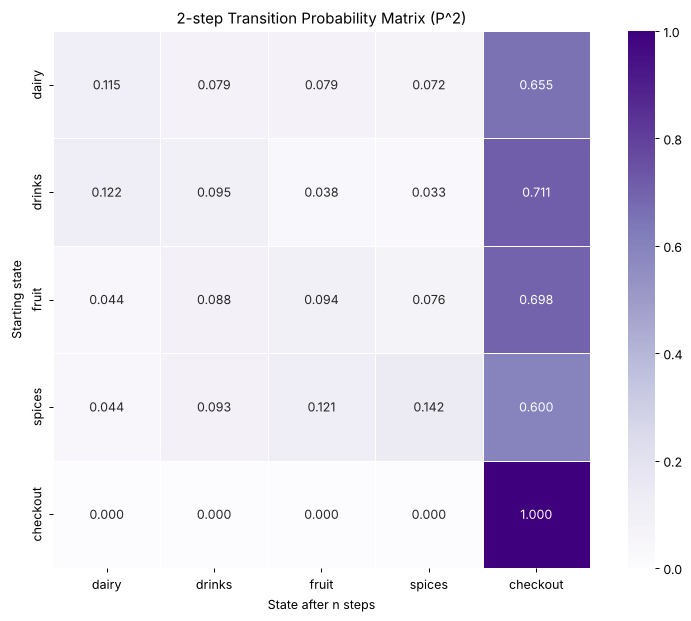

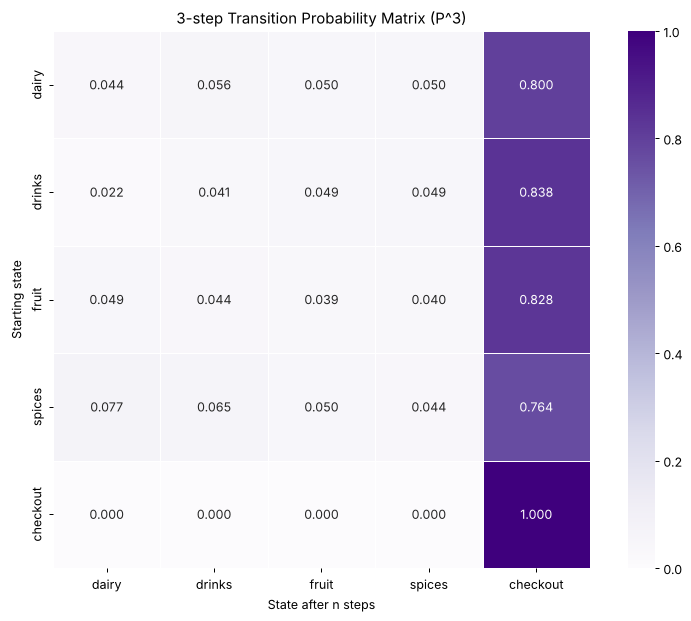

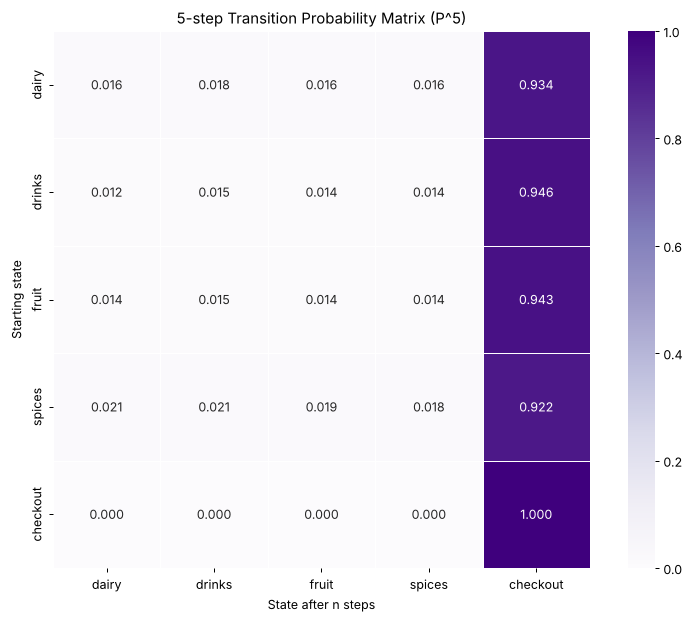

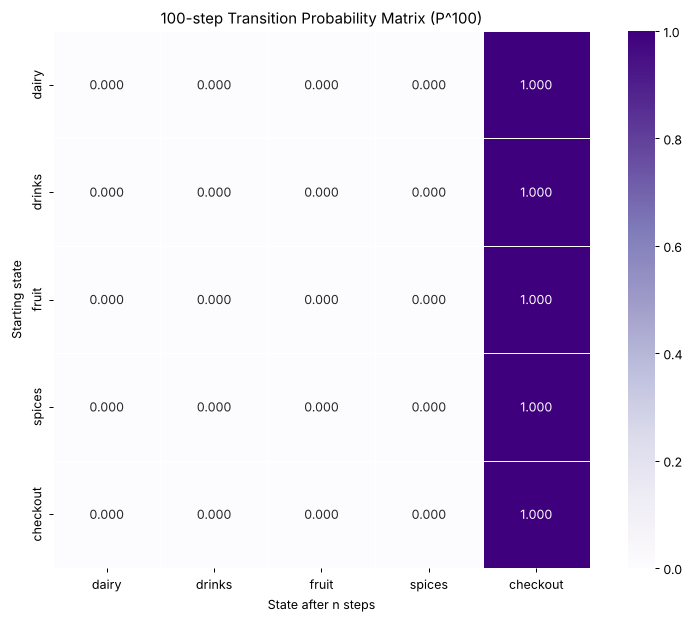


Selected n-step transition probabilities:

--- n = 2 ---
dairy -> checkout in 2 steps: 0.6550
drinks -> checkout in 2 steps: 0.7115
fruit -> checkout in 2 steps: 0.6975
spices -> checkout in 2 steps: 0.6003
dairy -> drinks in 2 steps: 0.0793
drinks -> fruit in 2 steps: 0.0382

--- n = 3 ---
dairy -> checkout in 3 steps: 0.7999
drinks -> checkout in 3 steps: 0.8377
fruit -> checkout in 3 steps: 0.8282
spices -> checkout in 3 steps: 0.7635
dairy -> drinks in 3 steps: 0.0560
drinks -> fruit in 3 steps: 0.0491

--- n = 100 ---
dairy -> checkout in 100 steps: 1.0000
drinks -> checkout in 100 steps: 1.0000
fruit -> checkout in 100 steps: 1.0000
spices -> checkout in 100 steps: 1.0000
dairy -> drinks in 100 steps: 0.0000
drinks -> fruit in 100 steps: 0.0000


In [ ]:
def power_matrix(P_df, n):
    """Compute P^n and keep the state labels."""
    values = np.linalg.matrix_power(P_df.to_numpy(dtype=float), n)
    return pd.DataFrame(values, index=P_df.index, columns=P_df.columns)

step_numbers = [2, 3, 5, LARGE_N]
P_powers = {}

for n in step_numbers:
    P_powers[n] = power_matrix(P, n)
    print(f"\nP^{n}:")
    display(P_powers[n].round(4))

for n in step_numbers:
    plt.figure(figsize=(9, 7))
    sns.heatmap(P_powers[n], annot=True, fmt=".3f", cmap="Purples",
                vmin=0, vmax=1, linewidths=0.5, square=True)
    plt.title(f"{n}-step Transition Probability Matrix (P^{n})")
    plt.xlabel("State after n steps")
    plt.ylabel("Starting state")
    plt.tight_layout()
    plt.show()

selected_pairs = [
    ("dairy", "checkout"),
    ("drinks", "checkout"),
    ("fruit", "checkout"),
    ("spices", "checkout"),
    ("dairy", "drinks"),
    ("drinks", "fruit"),
]

print("\nSelected n-step transition probabilities:")
for n in [2, 3, LARGE_N]:
    print(f"\n--- n = {n} ---")
    for start, end in selected_pairs:
        probability = P_powers[n].loc[start, end]
        print(f"{start} -> {end} in {n} steps: {probability:.4f}")

## 6. State distribution after n steps

Initial distribution pi_0:


,probability
location,
dairy,0.2876
drinks,0.1535
fruit,0.3774
spices,0.1815
checkout,0.0000



State distribution after 0 steps (pi_0 P^0):


,n=0
location,
dairy,0.2876
drinks,0.1535
fruit,0.3774
spices,0.1815
checkout,0.0000



State distribution after 1 steps (pi_0 P^1):


,n=1
next_location,
dairy,0.1528
drinks,0.1652
fruit,0.1159
spices,0.1371
checkout,0.4290


... (6 outputs left out)


State distribution after 10 steps (pi_0 P^10):


,n=10
next_location,
dairy,0.0010
drinks,0.0011
fruit,0.0010
spices,0.0010
checkout,0.9960



State distribution after 100 steps (pi_0 P^100):


,n=100
next_location,
dairy,0.0
drinks,0.0
fruit,0.0
spices,0.0
checkout,1.0


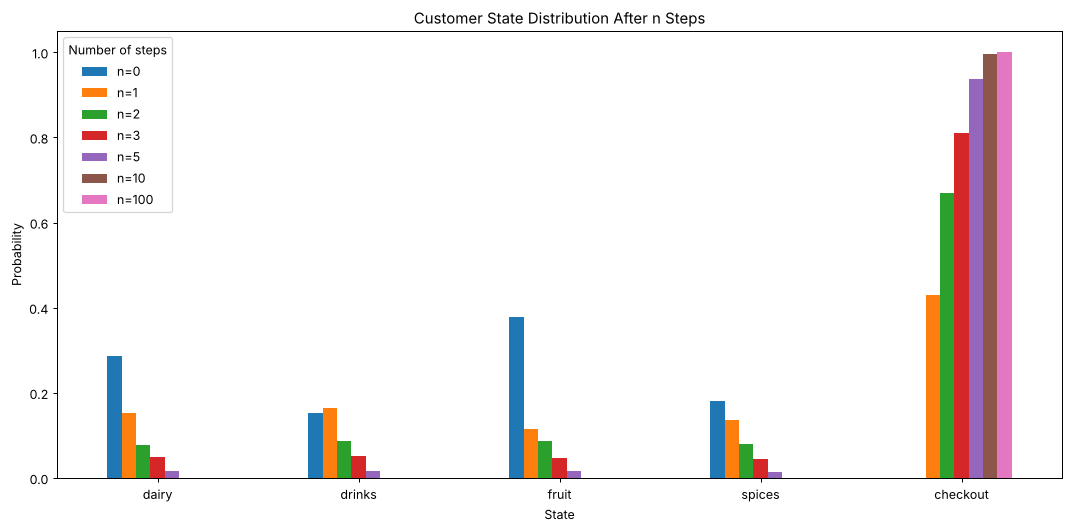


Probability of being in Checkout after n steps, by starting state:


,n=2,n=3,n=100
location,,,
dairy,0.6550,0.7999,1.0
drinks,0.7115,0.8377,1.0
fruit,0.6975,0.8282,1.0
spices,0.6003,0.7635,1.0
checkout,1.0000,1.0000,1.0


In [ ]:
# Initial distribution: the first department of each journey.
first_locations = journeys.apply(lambda path: path[0])
pi0 = first_locations.value_counts(normalize=True).reindex(STATES, fill_value=0.0)
pi0 = pi0 / pi0.sum()

print("Initial distribution pi_0:")
display(pi0.to_frame("probability").round(4))

def distribution_after_n(initial_distribution, transition_matrix, n):
    matrix_n = np.linalg.matrix_power(transition_matrix.to_numpy(dtype=float), n)
    values = initial_distribution.to_numpy(dtype=float) @ matrix_n
    return pd.Series(values, index=transition_matrix.columns, name=f"n={n}")

n_values_for_distribution = [0, 1, 2, 3, 5, 10, LARGE_N]
state_distributions = {}

for n in n_values_for_distribution:
    if n == 0:
        state_distributions[n] = pi0.copy()
        state_distributions[n].name = "n=0"
    else:
        state_distributions[n] = distribution_after_n(pi0, P, n)
    print(f"\nState distribution after {n} steps (pi_0 P^{n}):")
    display(state_distributions[n].to_frame().round(4))

distribution_plot = pd.DataFrame({
    f"n={n}": state_distributions[n] for n in n_values_for_distribution
})
distribution_plot.plot(kind="bar", figsize=(12, 6))
plt.title("Customer State Distribution After n Steps")
plt.xlabel("State")
plt.ylabel("Probability")
plt.xticks(rotation=0)
plt.legend(title="Number of steps")
plt.tight_layout()
plt.show()

checkout_probability_table = pd.DataFrame({
    f"n={n}": P_powers[n][TERMINAL_STATE] for n in [2, 3, LARGE_N]
})
print("\nProbability of being in Checkout after n steps, by starting state:")
display(checkout_probability_table.round(4))

## 7. Most likely next department

In [ ]:
for state in STATES:
    destinations = P.loc[state].drop(labels=[TERMINAL_STATE], errors="ignore")
    if len(destinations) and destinations.sum() > 0:
        most_likely = destinations.idxmax()
        print(f"From {state}, the most likely non-checkout destination is "
              f"{most_likely} ({destinations[most_likely]:.3f}).")
    elif state == TERMINAL_STATE:
        print("Checkout is absorbing: P[checkout, checkout] = 1.")

print(f"\nProbability of being in Checkout after {LARGE_N} steps "
      f"(from the initial distribution): {state_distributions[LARGE_N][TERMINAL_STATE]:.4f}")

From dairy, the most likely non-checkout destination is drinks (0.223).
From drinks, the most likely non-checkout destination is fruit (0.219).
From fruit, the most likely non-checkout destination is dairy (0.238).
From spices, the most likely non-checkout destination is dairy (0.324).
Checkout is absorbing: P[checkout, checkout] = 1.

Probability of being in Checkout after 100 steps (from the initial distribution): 1.0000
